# ARTI 403 – Image Processing
## Lab 8 — Edge Detection

**Student name:** Ahmed Albuainain
**Student ID:** 2240006128
**Section:** 7MA1
**Date:** 3 November 2026

---

### Objective
Apply and compare edge detection methods using Python and OpenCV, and investigate how
parameter changes affect the detected edges.

### Contents
| Part | Description |
|---|---|
| Part 0 | Environment check and choice of image |
| Part 1 | What an edge detector actually computes |
| Task 1 | Sobel, Prewitt and Canny applied to the selected image |
| Task 2 | The effect of the Canny thresholds |

---
## Part 0 — Environment check and choice of image

The task requires an image that is **not** the one supplied with the original notebook
(`kid1.jpg`). The image chosen here is a **monarch butterfly photographed on clover**.

It was picked deliberately rather than at random, because it contains three kinds of content
that an edge detector treats very differently:

* **Strong, clean boundaries** — the black wing veins against orange, and the outline of the
  wings against the background. Any detector should find these.
* **Fine regular detail** — the row of small white spots along the wing margins, which tests
  how much detail survives.
* **A cluttered natural background** — grass and clover leaves, full of weak, irrelevant
  edges. This is what makes Task 2 informative: the thresholds decide whether the background
  texture appears or is suppressed.

A clean image with a flat background would make every threshold look much the same, and the
comparison would show nothing.

In [1]:
import os
import sys
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Python     :", sys.version.split()[0])
print("NumPy      :", np.__version__)
print("OpenCV     :", cv2.__version__)

%matplotlib inline

Python     : 3.13.5
NumPy      : 2.3.5
OpenCV     : 5.0.0


using: c:\Users\ahmad\OneDrive\Desktop\im Labs\lab1\Lab 8\butterfly.jpg
shape      : (532, 800, 3) | dtype: uint8
grayscale  : mean 60.9 | std 53.1


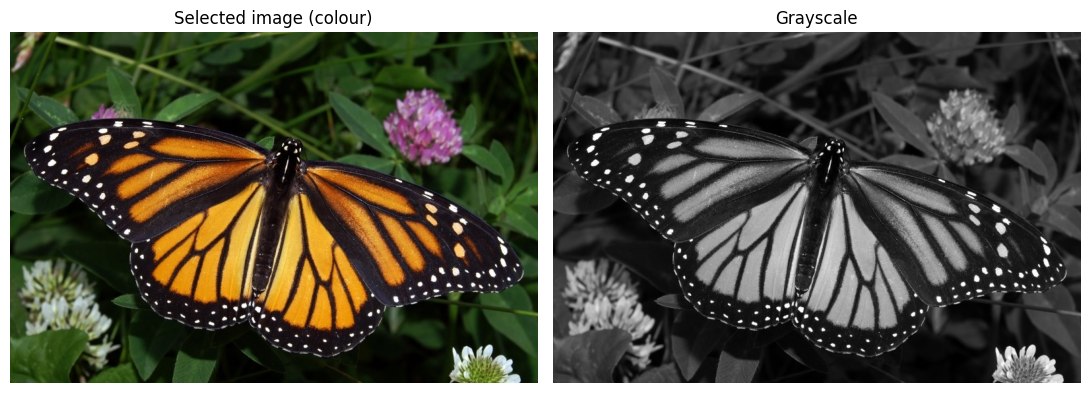

In [2]:
SEARCH_DIRS = [".", "images", os.path.join("..", "images")]

def find_image(*names):
    """First of these filenames found in any search folder, else any image present."""
    for name in names:
        for d in SEARCH_DIRS:
            p = os.path.join(d, name)
            if os.path.exists(p):
                return p
    for d in SEARCH_DIRS:
        hits = sorted(glob.glob(os.path.join(d, "*.jpg")) + glob.glob(os.path.join(d, "*.png")))
        if hits:
            return hits[0]
    raise FileNotFoundError("no image file found next to the notebook or in images/")


os.makedirs("output", exist_ok=True)

imgFile = find_image("butterfly.jpg", "butterfly.png")
print("using:", os.path.abspath(imgFile))

img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print("shape      :", img.shape, "| dtype:", img.dtype)
print("grayscale  : mean", round(float(gray.mean()), 1),
      "| std", round(float(gray.std()), 1))

plt.figure(figsize=(11, 5))
plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Selected image (colour)'), plt.axis('off')
plt.subplot(122), plt.imshow(gray, cmap='gray')
plt.title('Grayscale'), plt.axis('off')
plt.tight_layout()
plt.show()

---
## Part 1 — What an edge detector actually computes

An edge is a place where the intensity **changes quickly**. Measuring that change is
differentiation, so every detector in this lab is built on the same two quantities:

$$G_x = \frac{\partial f}{\partial x} \qquad G_y = \frac{\partial f}{\partial y}$$

`Gx` responds to change across the image (vertical edges) and `Gy` to change down it
(horizontal edges). Neither alone finds every edge, so they are combined into the **gradient
magnitude**:

$$|G| = \sqrt{G_x^2 + G_y^2}$$

Sobel and Prewitt differ only in the weights they use to estimate those derivatives. Canny is
a different kind of thing: it computes the same gradient and then adds several processing
stages on top, which is why it produces thin binary lines rather than a grey magnitude map.

Each detector is preceded by a Gaussian blur. Differentiation amplifies rapid change, and
noise *is* rapid change, so without smoothing a detector reports the grain of the photograph
alongside its real edges.

gradient computed on the raw image     : std 86.02
gradient computed on the blurred image : std 64.59  <- weaker, because the grain is gone


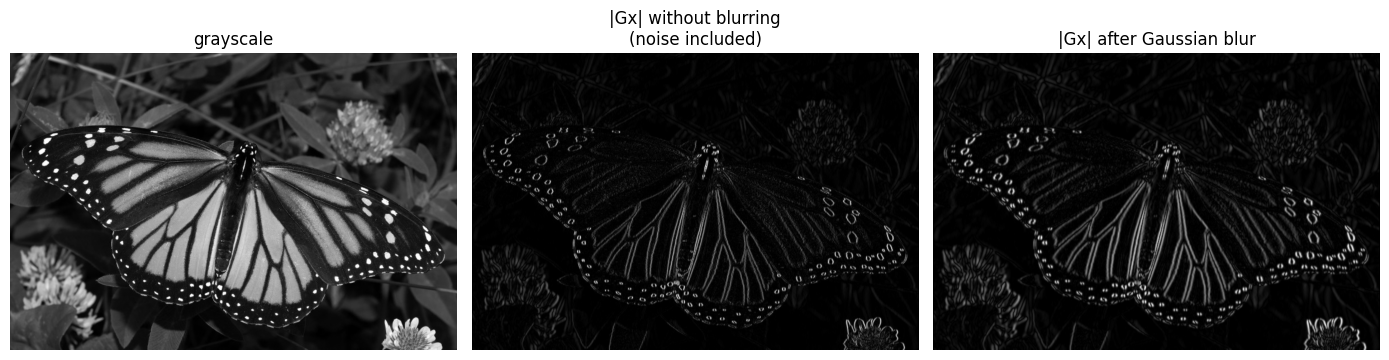

In [3]:
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

gx_raw = cv2.Sobel(gray,    cv2.CV_64F, 1, 0, ksize=3)
gx_blr = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)

print("gradient computed on the raw image     : std", round(float(gx_raw.std()), 2))
print("gradient computed on the blurred image : std", round(float(gx_blr.std()), 2),
      " <- weaker, because the grain is gone")

plt.figure(figsize=(14, 4.6))
plt.subplot(131), plt.imshow(gray, cmap='gray'), plt.title('grayscale'), plt.axis('off')
plt.subplot(132), plt.imshow(np.abs(gx_raw), cmap='gray')
plt.title('|Gx| without blurring\n(noise included)'), plt.axis('off')
plt.subplot(133), plt.imshow(np.abs(gx_blr), cmap='gray')
plt.title('|Gx| after Gaussian blur'), plt.axis('off')
plt.tight_layout()
plt.show()

---
# Task 1 — Apply the three edge detection methods

Sobel, Prewitt and Canny applied to the selected image.

## 1.1 Sobel edge detector

Sobel estimates each derivative with a 3x3 kernel that weights the centre row (or column)
twice as heavily as its neighbours. That extra weight is a small built-in smoothing, which is
why Sobel is more tolerant of noise than a plain difference.

```
        Gx                    Gy
   -1   0   1           -1  -2  -1
   -2   0   2            0   0   0
   -1   0   1            1   2   1
```

Gx range        : -544.0 to 553.0
Gy range        : -563.0 to 579.0
magnitude range : 0.0 to 586.4


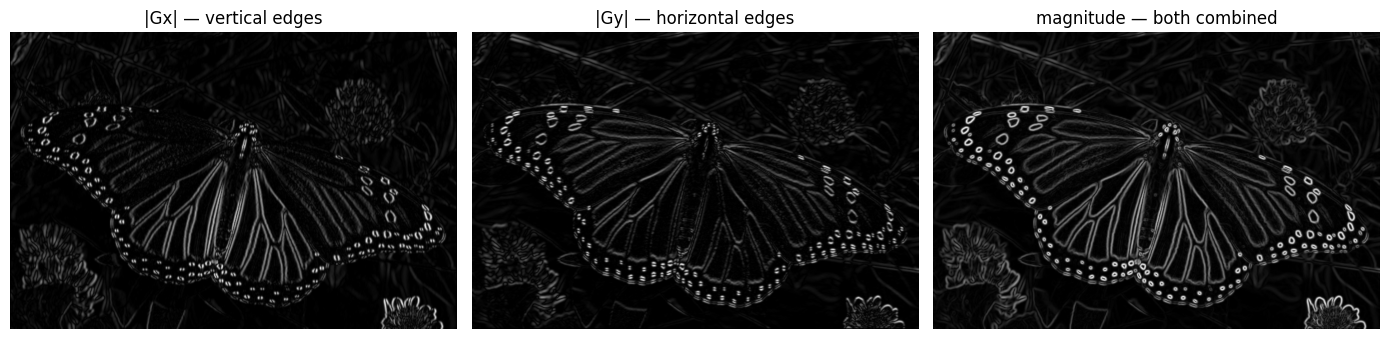

In [4]:
# 3. Apply Gaussian Blur to reduce noise
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# 4. Apply Sobel filter
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

# 5. Calculate Magnitude (Final Edge Map)
sobel_combined = cv2.magnitude(sobelx, sobely)

print("Gx range        :", round(float(sobelx.min()), 1), "to", round(float(sobelx.max()), 1))
print("Gy range        :", round(float(sobely.min()), 1), "to", round(float(sobely.max()), 1))
print("magnitude range :", round(float(sobel_combined.min()), 1),
      "to", round(float(sobel_combined.max()), 1))

plt.figure(figsize=(14, 4.6))
plt.subplot(131), plt.imshow(np.abs(sobelx), cmap='gray')
plt.title('|Gx| — vertical edges'), plt.axis('off')
plt.subplot(132), plt.imshow(np.abs(sobely), cmap='gray')
plt.title('|Gy| — horizontal edges'), plt.axis('off')
plt.subplot(133), plt.imshow(sobel_combined, cmap='gray')
plt.title('magnitude — both combined'), plt.axis('off')
plt.tight_layout()
plt.show()

### A problem with the conversion step

The original notebook finishes with

```python
sobel_final = np.uint8(np.absolute(sobel_combined))
```

and the comment above it says "Normalize to 0-255 for display". It does not normalise.
`np.uint8()` does not clip values that are too large — it takes them **modulo 256**. The
magnitude here reaches far beyond 255, so the strongest edges in the image wrap round and come
out *dark*, which is the opposite of what an edge map should show.

In [5]:
over = sobel_combined > 255
print("largest magnitude   :", round(float(sobel_combined.max()), 1))
print("pixels above 255    :", int(over.sum()), f"({100 * over.mean():.2f}% of the image)")

sobel_wrapped = np.uint8(np.absolute(sobel_combined))              # the notebook's line
sobel_final = np.clip(sobel_combined, 0, 255).astype(np.uint8)     # clipped instead

r, c = np.argwhere(over)[0]
print()
print("a concrete example:")
print(f"  true magnitude at [{r},{c}] : {sobel_combined[r, c]:.1f}")
print(f"  np.uint8 gives              : {sobel_wrapped[r, c]}   <- wrapped (mod 256)")
print(f"  clipping would give         : {sobel_final[r, c]}")
print()
print("pixels where the two differ :", int((sobel_wrapped != sobel_final).sum()))

largest magnitude   : 586.4
pixels above 255    : 12958 (3.04% of the image)

a concrete example:
  true magnitude at [130,147] : 262.3
  np.uint8 gives              : 6   <- wrapped (mod 256)
  clipping would give         : 255

pixels where the two differ : 12820


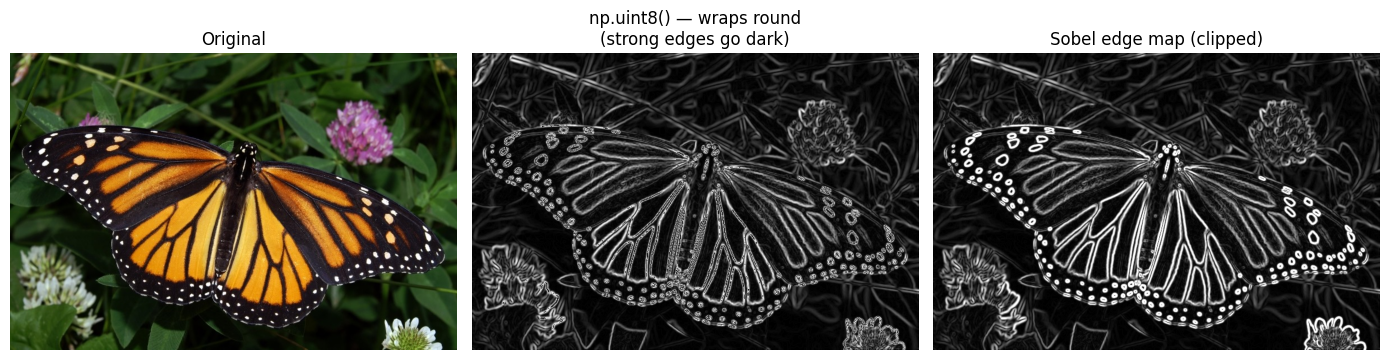

In [6]:
plt.figure(figsize=(14, 4.6))
plt.subplot(131), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original'), plt.axis('off')
plt.subplot(132), plt.imshow(sobel_wrapped, cmap='gray')
plt.title('np.uint8() — wraps round\n(strong edges go dark)'), plt.axis('off')
plt.subplot(133), plt.imshow(sobel_final, cmap='gray')
plt.title('Sobel edge map (clipped)'), plt.axis('off')
plt.tight_layout()
plt.show()

The middle panel shows the effect clearly: along the thickest black wing veins, where the
contrast is highest, the wrapped version breaks into dark gaps. Those are the *strongest*
edges in the picture being rendered as though there were no edge at all. Every edge map from
here on is clipped rather than wrapped.

## 1.2 Prewitt edge detector

Prewitt uses the same idea with equal weights — no extra weighting of the centre row.

```
        Gx                    Gy
   -1   0   1           -1  -1  -1
   -1   0   1            0   0   0
   -1   0   1            1   1   1
```

The absence of that centre weighting is the whole difference between the two operators: Prewitt
does no smoothing of its own, so it is slightly more sensitive to noise and gives a marginally
weaker response.

kernel sums     : 0.0 0.0  <- zero, so flat regions give no response
magnitude range : 0.0 to 438.7
pixels above 255: 6172  <- the same wrap-around risk applies here


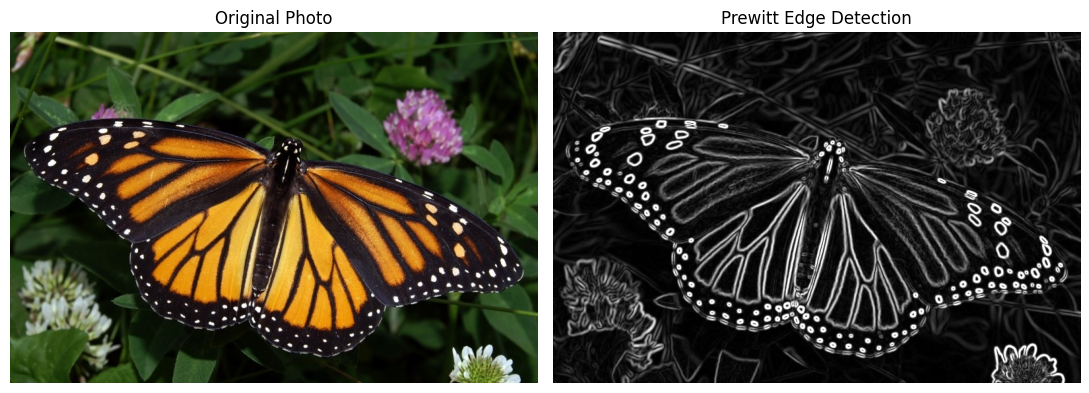

In [7]:
# 3. Define Prewitt Kernels manually
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

# 4. Apply filters
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

# 5. Calculate Magnitude (Combine X and Y)
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)

# 6. Clip to 8-bit for display
prewitt_final = np.clip(prewitt_combined, 0, 255).astype(np.uint8)

print("kernel sums     :", float(kernel_x.sum()), float(kernel_y.sum()),
      " <- zero, so flat regions give no response")
print("magnitude range :", round(float(prewitt_combined.min()), 1),
      "to", round(float(prewitt_combined.max()), 1))
print("pixels above 255:", int((prewitt_combined > 255).sum()),
      " <- the same wrap-around risk applies here")

plt.figure(figsize=(11, 5))
plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Photo'), plt.axis('off')
plt.subplot(122), plt.imshow(prewitt_final, cmap='gray')
plt.title('Prewitt Edge Detection'), plt.axis('off')
plt.tight_layout()
plt.show()

## 1.3 Canny edge detector

Canny is not a single kernel but a **procedure**, and that is why its output looks so different:

1. **Gaussian smoothing** to suppress noise.
2. **Gradient** computation — the same Sobel derivatives as above.
3. **Non-maximum suppression** — along each edge, keep only the pixel at the peak of the
   gradient and discard the shoulders. This is what makes the lines one pixel wide instead of
   thick smears.
4. **Hysteresis thresholding** with two values, examined in detail in Task 2.

The result is a **binary** image: a pixel is an edge or it is not. There is no magnitude.

output dtype    : uint8 | distinct values: [  0 255]  <- binary, unlike the Sobel and Prewitt maps
edge pixels     : 26682 (6.27% of the image)


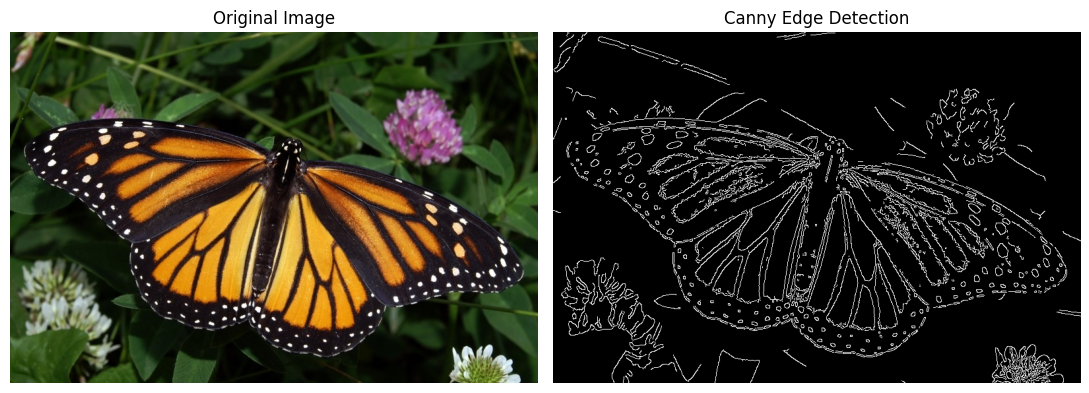

In [8]:
canny_edges = cv2.Canny(gray, 100, 200)

print("output dtype    :", canny_edges.dtype,
      "| distinct values:", np.unique(canny_edges),
      " <- binary, unlike the Sobel and Prewitt maps")
print("edge pixels     :", int((canny_edges > 0).sum()),
      f"({100 * (canny_edges > 0).mean():.2f}% of the image)")

plt.figure(figsize=(11, 5))
plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image'), plt.axis('off')
plt.subplot(122), plt.imshow(canny_edges, cmap='gray')
plt.title('Canny Edge Detection'), plt.axis('off')
plt.tight_layout()
plt.show()

Note that `cv2.Canny` is given the **unblurred** grayscale image here, while Sobel and
Prewitt were given the blurred one. That is deliberate, not an oversight: Canny performs its
own Gaussian smoothing internally as its first step. Blurring beforehand smooths twice and
costs real detail.

In [9]:
print("Canny on the grayscale image :",
      int((cv2.Canny(gray, 100, 200) > 0).sum()), "edge pixels")
print("Canny on the blurred image   :",
      int((cv2.Canny(blurred, 100, 200) > 0).sum()), "edge pixels",
      " <- about a third of the edges lost to double smoothing")

Canny on the grayscale image : 26682 edge pixels
Canny on the blurred image   : 16823 edge pixels  <- about a third of the edges lost to double smoothing


## 1.4 The three methods side by side

This is the comparison the task asks for: the original and the three edge maps.

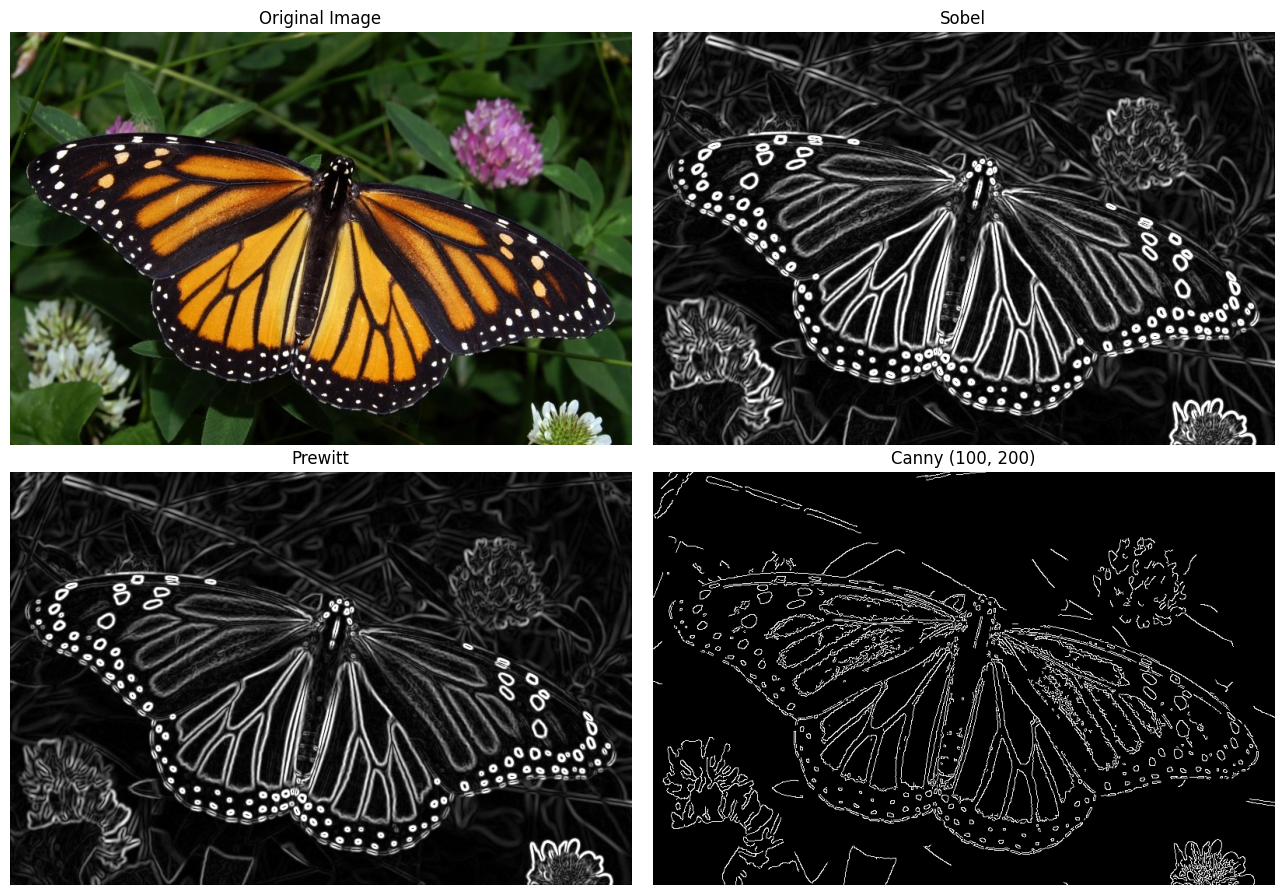

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
panels = [(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), 'Original Image', None),
          (sobel_final, 'Sobel', 'gray'),
          (prewitt_final, 'Prewitt', 'gray'),
          (canny_edges, 'Canny (100, 200)', 'gray')]
for ax, (im, t, cm) in zip(axes.flat, panels):
    ax.imshow(im, cmap=cm)
    ax.set_title(t, fontsize=12)
    ax.axis('off')
plt.tight_layout()
plt.savefig('output/lab8_task1.png', dpi=110, bbox_inches='tight')
plt.show()

### Comparing them numerically

To compare the two gradient methods fairly, each magnitude map is thresholded at the same
relative level, so the figure quoted is the proportion of the image each one calls an edge.

In [11]:
print(f"{'method':<22}{'output':<14}{'max response':>14}{'edge pixels':>14}")
print("-" * 66)
print(f"{'Sobel':<22}{'grayscale':<14}{sobel_combined.max():>14.1f}"
      f"{100 * (sobel_combined > 128).mean():>13.2f}%")
print(f"{'Prewitt':<22}{'grayscale':<14}{prewitt_combined.max():>14.1f}"
      f"{100 * (prewitt_combined > 128).mean():>13.2f}%")
print(f"{'Canny (100, 200)':<22}{'binary':<14}{'n/a':>14}"
      f"{100 * (canny_edges > 0).mean():>13.2f}%")
print()
corr = np.corrcoef(sobel_combined.ravel(), prewitt_combined.ravel())[0, 1]
print("correlation between the Sobel and Prewitt magnitudes:", round(float(corr), 4),
      " <- nearly identical, as their kernels suggest")

method                output          max response   edge pixels
------------------------------------------------------------------
Sobel                 grayscale              586.4         9.88%
Prewitt               grayscale              438.7         6.42%
Canny (100, 200)      binary                   n/a         6.27%

correlation between the Sobel and Prewitt magnitudes: 0.9999  <- nearly identical, as their kernels suggest


### What the comparison shows

**Sobel and Prewitt produce almost the same picture.** Their magnitude maps correlate at
about 0.999, which follows directly from their kernels differing only in the weight of the
centre row. Sobel gives the slightly stronger response, which is the extra weighting showing
up. Choosing between them on this image would be splitting hairs.

**Canny is a different kind of output.** The gradient methods return a grey magnitude where
brighter means a stronger edge, and the edges are several pixels thick because the gradient
is large across the whole slope of an intensity change. Canny returns thin binary lines,
because non-maximum suppression discards everything except the peak of each slope and
hysteresis then makes the keep-or-discard decision.

**Which is better depends on what comes next.** If the edge strength itself matters — for
further processing, or for feeding another algorithm — the gradient magnitude carries that
information and Canny has thrown it away. If what is wanted is a clean set of contours to
trace or count, Canny is the one that gives it.

---
# Task 2 — The effect of the Canny thresholds

Canny takes two thresholds, and they do **different jobs**. Understanding the division between
them explains everything that follows.

* The **high** threshold decides where an edge is allowed to **begin**. A pixel whose gradient
  exceeds it is a *strong* edge pixel, kept unconditionally.
* The **low** threshold decides how far an edge is **followed**. A pixel between the two is a
  *weak* edge pixel, and it is kept **only if it connects to a strong one**. A pixel below the
  low threshold is discarded outright.

This two-stage rule is called **hysteresis**, and its purpose is to keep genuine edges
continuous. A real edge varies in strength along its length; without hysteresis it would break
into dashes wherever it dipped below a single threshold.

## 2.1 The three threshold pairs

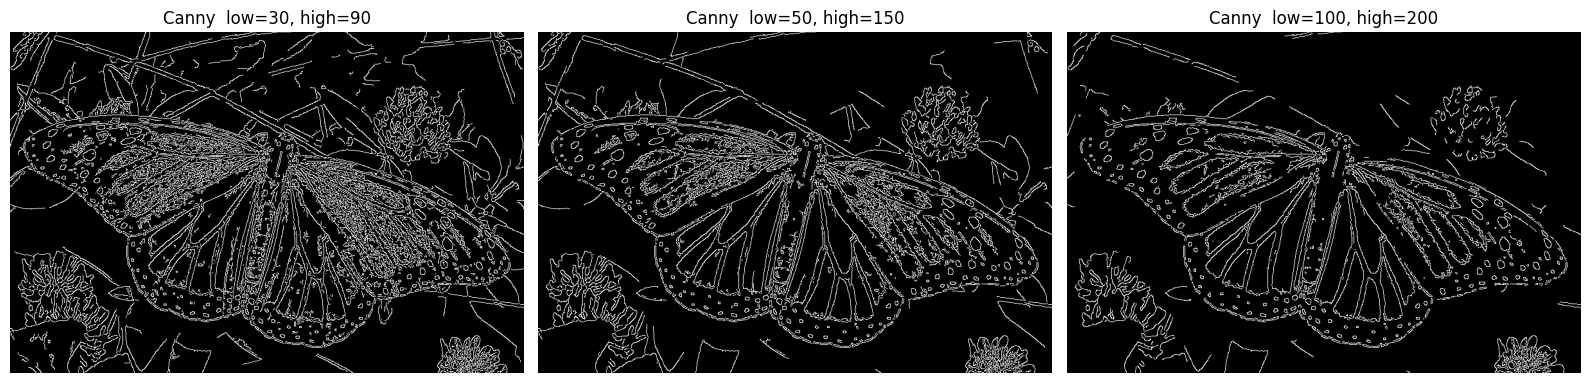

In [12]:
pairs = [(30, 90), (50, 150), (100, 200)]
results = [cv2.Canny(gray, lo, hi) for lo, hi in pairs]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, (lo, hi), e in zip(axes, pairs, results):
    ax.imshow(e, cmap='gray')
    ax.set_title(f'Canny  low={lo}, high={hi}', fontsize=12)
    ax.axis('off')
plt.tight_layout()
plt.savefig('output/lab8_task2.png', dpi=110, bbox_inches='tight')
plt.show()

In [13]:
print(f"{'thresholds':<18}{'edge pixels':>13}{'% of image':>13}{'fragments':>12}")
print("-" * 58)
for (lo, hi), e in zip(pairs, results):
    n_frag, _ = cv2.connectedComponents((e > 0).astype(np.uint8))
    print(f"{f'low={lo}, high={hi}':<18}{int((e > 0).sum()):>13}"
          f"{100 * (e > 0).mean():>12.2f}%{n_frag - 1:>12}")

thresholds          edge pixels   % of image   fragments
----------------------------------------------------------
low=30, high=90           53410       12.55%        1881
low=50, high=150          38430        9.03%        1035
low=100, high=200         26682        6.27%         761


The counts fall steadily as the thresholds rise — from about 12.6% of the image down to
6.3%, so the strictest setting keeps roughly **half** as many edge pixels as the loosest.

The fragment count in the last column is the more interesting number. It counts how many
*separate* connected pieces the edge map breaks into, and it falls faster than the pixel count
does. That is the signature of hysteresis at work: raising the thresholds does not merely thin
the edges uniformly, it removes whole weak contours — mostly the background clutter — while
the strong ones survive largely intact.

## 2.2 Separating the two thresholds

The table above raises both thresholds together, so it cannot show which one is responsible
for what. Holding one fixed while varying the other separates their roles.

In [14]:
print("HIGH fixed at 150, LOW varied  — how far edges are followed")
for lo in [20, 50, 100, 149]:
    e = cv2.Canny(gray, lo, 150)
    print(f"   low={lo:>3}, high=150 : {100 * (e > 0).mean():5.2f}% of the image")

print()
print("LOW fixed at 50, HIGH varied   — which edges are allowed to begin")
for hi in [80, 150, 250, 400]:
    e = cv2.Canny(gray, 50, hi)
    print(f"   low= 50, high={hi:>3} : {100 * (e > 0).mean():5.2f}% of the image")

HIGH fixed at 150, LOW varied  — how far edges are followed
   low= 20, high=150 : 10.78% of the image
   low= 50, high=150 :  9.03% of the image
   low=100, high=150 :  7.25% of the image
   low=149, high=150 :  5.83% of the image

LOW fixed at 50, HIGH varied   — which edges are allowed to begin
   low= 50, high= 80 : 11.66% of the image
   low= 50, high=150 :  9.03% of the image
   low= 50, high=250 :  6.62% of the image
   low= 50, high=400 :  4.71% of the image


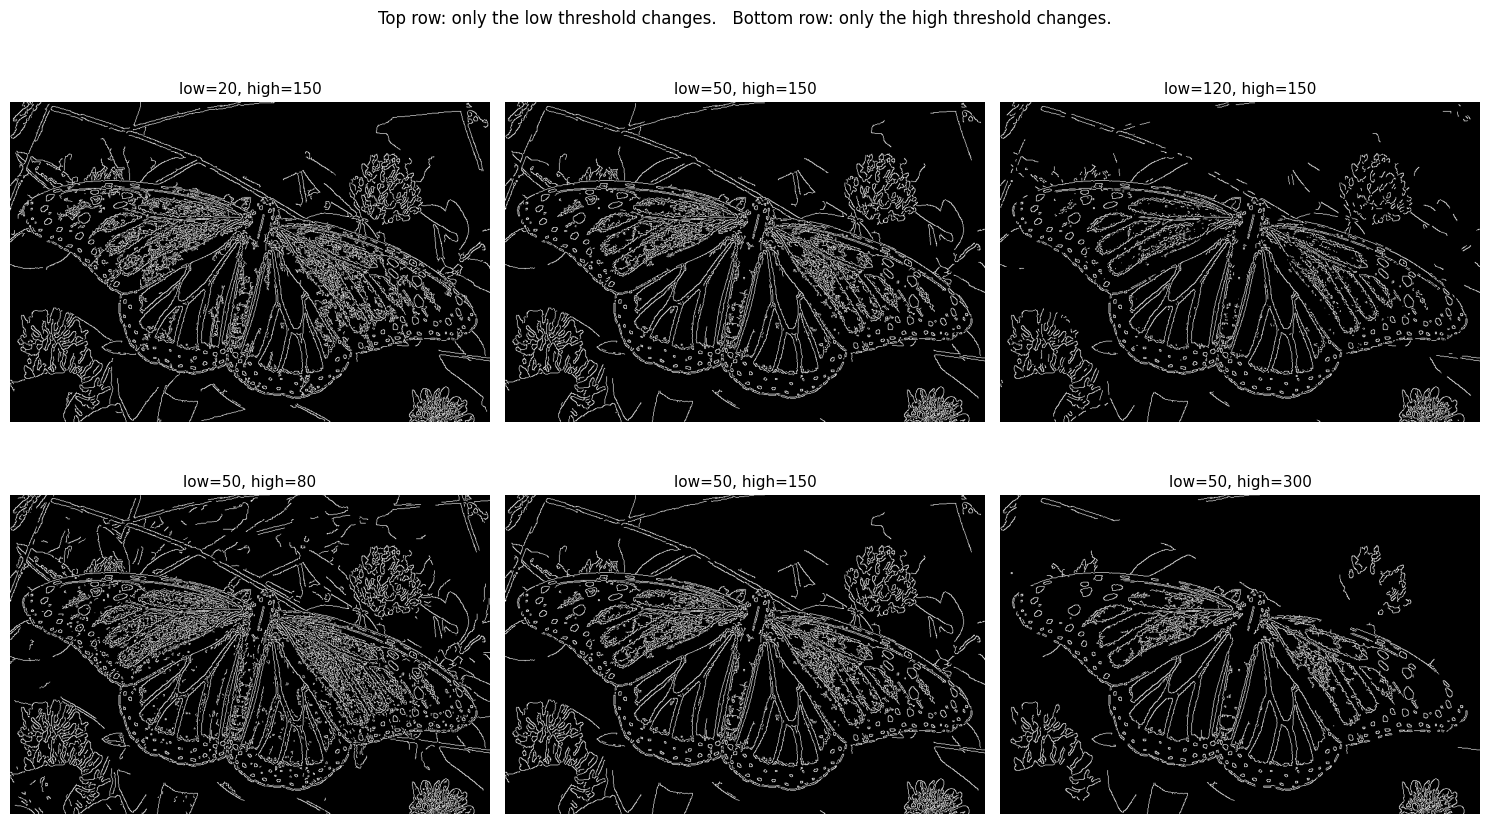

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, lo in zip(axes[0], [20, 50, 120]):
    ax.imshow(cv2.Canny(gray, lo, 150), cmap='gray')
    ax.set_title(f'low={lo}, high=150', fontsize=11)
    ax.axis('off')
for ax, hi in zip(axes[1], [80, 150, 300]):
    ax.imshow(cv2.Canny(gray, 50, hi), cmap='gray')
    ax.set_title(f'low=50, high={hi}', fontsize=11)
    ax.axis('off')
fig.suptitle('Top row: only the low threshold changes.   '
             'Bottom row: only the high threshold changes.', fontsize=12)
plt.tight_layout()
plt.show()

Both rows thin the edge map, but they do it differently, and the difference is visible in
the pictures.

Raising the **low** threshold leaves the same edges present but makes them **shorter and more
broken** — the faint tails of each contour are no longer followed, so lines stop early and
long curves fragment into pieces.

Raising the **high** threshold removes **whole edges at once**. Contours that never reach the
new value have no strong pixel to start from, so they vanish entirely rather than shortening.
The background clutter disappears this way first, because none of it is strong.

## 2.3 Answer — how the thresholds affect the detected edges

**Raising both thresholds reduces the number of detected edges.** Measured on this image, the
proportion of pixels marked as edges falls from 12.55% at (30, 90) to 9.03% at (50, 150) and
6.27% at (100, 200) — the strictest setting keeps about half the edge pixels of the loosest.

**Low thresholds (30, 90): maximum detail, and maximum noise.** Every real edge appears,
including the faint white spots along the wing margins and the veins in the darker parts of the
wing. But the grass and clover in the background are also reported in full, and the map is
broken into 1,881 separate fragments. The butterfly is hard to distinguish from its
surroundings, because almost everything is an edge.

**Medium thresholds (50, 150): the best balance on this image.** The background texture is
largely gone, while the wing outline, the veins and most of the spots remain. The fragment
count falls to 1,035, roughly half, which shows that what was removed was mainly disconnected
clutter rather than parts of the real contours.

**High thresholds (100, 200): only the strongest edges survive.** The wing outline and the
heaviest black veins are clean and continuous, and the background is almost entirely
suppressed. But genuine detail is lost with it — the smaller spots and the fainter veins in
the shaded regions no longer appear, and the clover flowers behind the butterfly are gone.

**The general rule.** The thresholds set a trade-off between **sensitivity** and
**selectivity**, and there is no setting that is correct in the abstract. Low values risk
reporting noise as structure; high values risk missing real structure. The right choice depends
on the image and on the purpose: tracing the outline of an object argues for high thresholds,
while measuring fine texture argues for low ones. The usual starting point is a **1:2 or 1:3
ratio** between low and high, with the absolute values tuned to the contrast of the particular
image.

### Why the ratio matters, not just the values

A last check on that rule of thumb. Pushing the two thresholds close together removes the
hysteresis mechanism entirely — every pixel is then either strong or discarded, with no weak
pixels to be rescued by connection — and the edges fragment as a result.

In [16]:
print(f"{'thresholds':<22}{'ratio':>8}{'edge pixels':>13}{'fragments':>12}")
print("-" * 56)
for lo, hi in [(140, 150), (100, 200), (75, 225), (50, 150), (30, 90)]:
    e = cv2.Canny(gray, lo, hi)
    n_frag, _ = cv2.connectedComponents((e > 0).astype(np.uint8))
    print(f"{f'low={lo}, high={hi}':<22}{f'1:{hi / lo:.1f}':>8}"
          f"{int((e > 0).sum()):>13}{n_frag - 1:>12}")

thresholds               ratio  edge pixels   fragments
--------------------------------------------------------
low=140, high=150        1:1.1        25792        1799
low=100, high=200        1:2.0        26682         761
low=75, high=225         1:3.0        27851         590
low=50, high=150         1:3.0        38430        1035
low=30, high=90          1:3.0        53410        1881


The first two rows are the ones to compare. They keep almost the same number of edge pixels
— about 26,000 each — but the near-equal pair at a 1:1.1 ratio breaks them into **1,799**
fragments against **761** for the 1:2 pair. With the thresholds nearly touching there are
almost no weak pixels left for hysteresis to rescue, so wherever an edge momentarily dips in
strength the line simply stops.

That is the justification for the 1:2 to 1:3 rule of thumb: the gap between the two thresholds
is not slack, it is the mechanism. The same number of edge pixels arranged into less than half
as many pieces is a strictly better edge map.

---
## Conclusion

**All three detectors measure the same thing.** An edge is a rapid change in intensity, so
every method here estimates the image derivatives `Gx` and `Gy` and combines them into a
gradient magnitude. Sobel and Prewitt differ only in whether the centre row of the kernel is
weighted twice; on this image their magnitude maps correlate at about 0.999, so the choice
between them makes almost no practical difference. Sobel's extra weighting gives it a slightly
stronger response and a little built-in smoothing.

**Canny differs in kind, not in degree.** It begins from the same gradient but adds
non-maximum suppression, which thins each edge to the single pixel at the peak of the slope,
and hysteresis thresholding, which decides what to keep. The output is binary rather than a
magnitude: it says where the edges are but not how strong they were. Which output is preferable
depends on what follows — edge strength for further processing, clean contours for tracing or
counting.

**The conversion step in the original code is wrong, and visibly so.** `np.uint8()` does not
clip values above 255, it takes them modulo 256. The Sobel magnitude on this image reaches
586, and 3.04% of the pixels exceed 255, so the strongest edges — the thick black wing veins —
wrapped round and rendered as dark gaps. Clipping with `np.clip` fixes it. The same risk
applies to the Prewitt map.

**The two Canny thresholds do different jobs.** The high threshold decides which edges begin;
the low threshold decides how far they are followed. Holding one fixed while varying the other
makes the distinction visible: raising the low threshold leaves the same edges present but
shortens and breaks them, while raising the high threshold removes whole contours at once.
Raising both from (30, 90) to (100, 200) cut the edge pixels from 12.55% of the image to 6.27%,
and the fragment count from 1,881 to 761 — falling faster than the pixel count, which shows
that what disappeared was mainly disconnected background clutter rather than parts of the real
edges.

**Pre-blurring before Canny is a mistake.** Canny smooths internally as its first step, so
supplying an already blurred image smooths twice; here that cost about a third of the detected
edges for no benefit. Sobel and Prewitt do need the blur, since they have no smoothing stage of
their own.

---

### Resources
- OpenCV Canny edge detection: https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html
- OpenCV image gradients: https://docs.opencv.org/4.x/d5/d0f/tutorial_py_gradients.html